# CV01 — Hà Duy Hưng: Tiền xử lý dữ liệu & Sinh đặc trưng độ trễ

**Môn học:** Quản lý & Khai phá Chuỗi Thời Gian (QLCTG) — Lab 3  
**Thành viên phụ trách:** Hà Duy Hưng (Nhóm trưởng)  
**Dữ liệu đầu vào:** `data/raw/AEP_hourly.csv`  
**Sản phẩm đầu ra:**  
- `data/processed/train.csv`, `test.csv`, `AEP_features.csv`  
- `outputs/tables/cv01_data_summary.csv`, `train_test_split_info.csv`  
- `outputs/figures/cv01_raw_and_lags.png`, `eda_aep_hourly.png`  

---

## 1. Cấu hình môi trường & đường dẫn

In [2]:
import sys
import os
from pathlib import Path
from typing import Tuple, List

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

# Đường dẫn gốc dự án (notebook nằm trong notebooks/, lên 1 cấp là project root)
NOTEBOOK_DIR = Path().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent

DATA_RAW      = PROJECT_ROOT / 'data' / 'raw'       / 'AEP_hourly.csv'
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'
FIGURES_DIR   = PROJECT_ROOT / 'outputs' / 'figures'
TABLES_DIR    = PROJECT_ROOT / 'outputs' / 'tables'
MODELS_DIR    = PROJECT_ROOT / 'outputs' / 'models'

for d in [DATA_PROCESSED, FIGURES_DIR, TABLES_DIR, MODELS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CONFIG = {
    'datetime_col': 'Datetime',
    'target_col':   'AEP_MW',
    'lags': [1, 2, 3, 24, 48, 168],
    'train_ratio': 0.80,
    'random_state': 42,
}

print(f'Project root : {PROJECT_ROOT}')
print(f'Dữ liệu thô  : {DATA_RAW.exists()} — {DATA_RAW}')

Project root : E:\Chuỗi_TG\time-series-lab2
Dữ liệu thô  : True — E:\Chuỗi_TG\time-series-lab2\data\raw\AEP_hourly.csv


## Bước 1 — Tải & kiểm toán dữ liệu gốc

In [3]:
if not DATA_RAW.exists():
    raise FileNotFoundError(f'Không tìm thấy: {DATA_RAW}')

df = pd.read_csv(DATA_RAW)
raw_count = len(df)
print(f'Số dòng thô: {raw_count:,}')

# Thiết lập DatetimeIndex
df['Datetime'] = pd.to_datetime(df['Datetime'])
df.set_index('Datetime', inplace=True)
df.sort_index(inplace=True)

missing_count   = int(df['AEP_MW'].isna().sum())
duplicate_count = int(df.index.duplicated().sum())
print(f'Giá trị NaN        : {missing_count}')
print(f'Trùng lặp (DST)    : {duplicate_count}')

if duplicate_count > 0:
    df = df.groupby(df.index).mean()
    print(f'Đã gộp trùng lặp. Còn lại: {len(df):,} dòng')

df.head(3)

Số dòng thô: 121,273
Giá trị NaN        : 0
Trùng lặp (DST)    : 4
Đã gộp trùng lặp. Còn lại: 121,269 dòng


,AEP_MW
Datetime,
2004-10-01 01:00:00,12379.0
2004-10-01 02:00:00,11935.0
2004-10-01 03:00:00,11692.0


In [4]:
# Bảng thống kê mô tả
stats = df['AEP_MW'].describe()
summary_rows = [
    {'Chỉ số': 'Mốc bắt đầu',    'Giá trị': str(df.index.min())},
    {'Chỉ số': 'Mốc kết thúc',   'Giá trị': str(df.index.max())},
    {'Chỉ số': 'Tổng quan sát',  'Giá trị': f'{len(df):,}'},
    {'Chỉ số': 'Số NaN',         'Giá trị': f'{missing_count:,}'},
    {'Chỉ số': 'Mean (MW)',       'Giá trị': f"{stats['mean']:.2f}"},
    {'Chỉ số': 'Std  (MW)',       'Giá trị': f"{stats['std']:.2f}"},
    {'Chỉ số': 'Min  (MW)',       'Giá trị': f"{stats['min']:.2f}"},
    {'Chỉ số': 'Max  (MW)',       'Giá trị': f"{stats['max']:.2f}"},
]
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(TABLES_DIR / 'cv01_data_summary.csv', index=False, encoding='utf-8-sig')
summary_df.to_csv(TABLES_DIR / 'data_summary.csv',      index=False, encoding='utf-8-sig')
print('✅ Đã lưu cv01_data_summary.csv')
summary_df

✅ Đã lưu cv01_data_summary.csv


,Chỉ số,Giá trị
0,Mốc bắt đầu,2004-10-01 01:00:00
1,Mốc kết thúc,2018-08-03 00:00:00
2,Tổng quan sát,"121,269"
3,Số NaN,0
4,Mean (MW),15499.65
5,Std (MW),2591.32
6,Min (MW),9581.00
7,Max (MW),25695.00


## Bước 2 — Tạo Lag Features & Calendar Features

In [5]:
df_feat = df.copy()
lags = CONFIG['lags']
target_col = CONFIG['target_col']

# Lag features: y_{t-1}, y_{t-2}, y_{t-3}, y_{t-24}, y_{t-48}, y_{t-168}
for lag in lags:
    df_feat[f'lag_{lag}'] = df_feat[target_col].shift(lag)

# Calendar features
df_feat['hour']      = df_feat.index.hour
df_feat['dayofweek'] = df_feat.index.dayofweek
df_feat['quarter']   = df_feat.index.quarter
df_feat['month']     = df_feat.index.month
df_feat['year']      = df_feat.index.year
df_feat['dayofyear'] = df_feat.index.dayofyear
df_feat['is_weekend']= (df_feat.index.dayofweek >= 5).astype(int)

before = len(df_feat)
df_feat.dropna(inplace=True)
dropped = before - len(df_feat)

print(f'Đã tạo {len(lags)} lag features + 7 calendar features')
print(f'Loại bỏ {dropped} dòng NaN đầu (lag tối đa = {max(lags)}h)')
print(f'Kích thước dữ liệu: {df_feat.shape}')
df_feat.head(3)

Đã tạo 6 lag features + 7 calendar features
Loại bỏ 168 dòng NaN đầu (lag tối đa = 168h)
Kích thước dữ liệu: (121101, 14)


,AEP_MW,lag_1,lag_2,lag_3,lag_24,lag_48,lag_168,hour,dayofweek,quarter,month,year,dayofyear,is_weekend
Datetime,,,,,,,,,,,,,,
2004-10-08 01:00:00,12468.0,13271.0,14359.0,15407.0,12484.0,12764.0,12379.0,1,4,4,10,2004,282,0
2004-10-08 02:00:00,12046.0,12468.0,13271.0,14359.0,12054.0,12347.0,11935.0,2,4,4,10,2004,282,0
2004-10-08 03:00:00,11749.0,12046.0,12468.0,13271.0,11745.0,12192.0,11692.0,3,4,4,10,2004,282,0


## Bước 3 — Phân chia Train / Test theo thời gian (80 / 20)

In [6]:
train_ratio = CONFIG['train_ratio']
train_size  = int(len(df_feat) * train_ratio)

train_df = df_feat.iloc[:train_size]
test_df  = df_feat.iloc[train_size:]

print(f'Train: {len(train_df):,} dòng  ({train_df.index.min()} → {train_df.index.max()})')
print(f'Test : {len(test_df):,} dòng  ({test_df.index.min()} → {test_df.index.max()})')

train_path = DATA_PROCESSED / 'train.csv'
test_path  = DATA_PROCESSED / 'test.csv'
all_path   = DATA_PROCESSED / 'AEP_features.csv'

train_df.to_csv(train_path, index=True)
test_df.to_csv(test_path,   index=True)
df_feat.to_csv(all_path,    index=True)
print('✅ Đã lưu train.csv, test.csv, AEP_features.csv')

split_info = pd.DataFrame([
    {'Tập': 'Train', 'Dòng': len(train_df), 'Tỷ lệ': '80%',
     'Bắt đầu': str(train_df.index.min()), 'Kết thúc': str(train_df.index.max())},
    {'Tập': 'Test',  'Dòng': len(test_df),  'Tỷ lệ': '20%',
     'Bắt đầu': str(test_df.index.min()),  'Kết thúc': str(test_df.index.max())},
])
split_info.to_csv(TABLES_DIR / 'train_test_split_info.csv', index=False, encoding='utf-8-sig')
split_info

Train: 96,880 dòng  (2004-10-08 01:00:00 → 2015-10-28 16:00:00)
Test : 24,221 dòng  (2015-10-28 17:00:00 → 2018-08-03 00:00:00)
✅ Đã lưu train.csv, test.csv, AEP_features.csv


,Tập,Dòng,Tỷ lệ,Bắt đầu,Kết thúc
0,Train,96880,80%,2004-10-08 01:00:00,2015-10-28 16:00:00
1,Test,24221,20%,2015-10-28 17:00:00,2018-08-03 00:00:00


## Bước 4 — Trực quan hóa: Chuỗi thời gian & Tương quan Lag

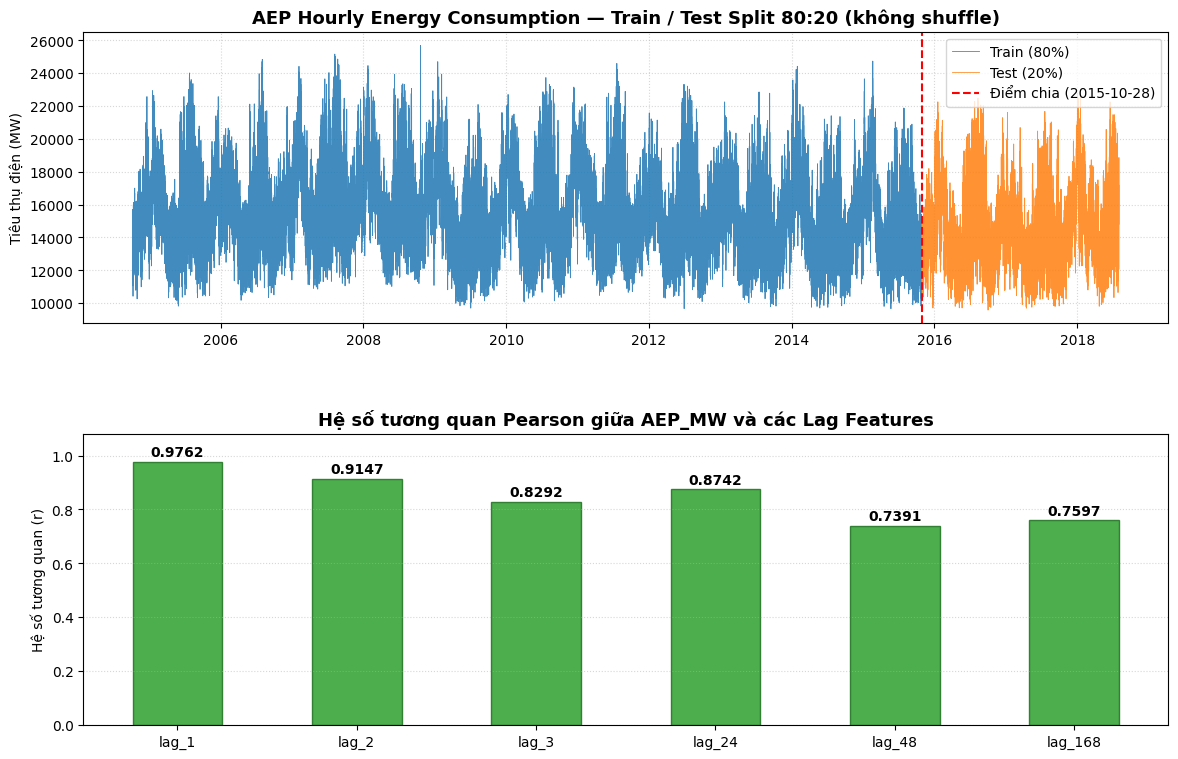

✅ Đã lưu: E:\Chuỗi_TG\time-series-lab2\outputs\figures\cv01_raw_and_lags.png


In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
plt.subplots_adjust(hspace=0.38)

# --- Subplot 1: Chuỗi Train vs Test ---
ax1 = axes[0]
ax1.plot(train_df.index, train_df[target_col], label='Train (80%)', color='#1f77b4', lw=0.6, alpha=0.85)
ax1.plot(test_df.index,  test_df[target_col],  label='Test (20%)',  color='#ff7f0e', lw=0.6, alpha=0.85)
split_time = test_df.index.min()
ax1.axvline(split_time, color='red', linestyle='--', lw=1.5, label=f'Điểm chia ({split_time.strftime("%Y-%m-%d")})')
ax1.set_title('AEP Hourly Energy Consumption — Train / Test Split 80:20 (không shuffle)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Tiêu thụ điện (MW)')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.5)

# --- Subplot 2: Pearson Correlation với các Lag ---
ax2 = axes[1]
lag_cols    = [f'lag_{lag}' for lag in lags]
correlations= [df_feat[target_col].corr(df_feat[col]) for col in lag_cols]
bars = ax2.bar(lag_cols, correlations, color='#2ca02c', edgecolor='#1e7120', alpha=0.85, width=0.5)
ax2.set_title('Hệ số tương quan Pearson giữa AEP_MW và các Lag Features', fontsize=13, fontweight='bold')
ax2.set_ylabel('Hệ số tương quan (r)')
ax2.set_ylim(0, 1.08)
ax2.grid(True, axis='y', linestyle=':', alpha=0.5)
for bar in bars:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.02, f'{h:.4f}', ha='center', fontsize=10, fontweight='bold')

fig_path = FIGURES_DIR / 'cv01_raw_and_lags.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'eda_aep_hourly.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'✅ Đã lưu: {fig_path}')

## ✅ CV01 Hoàn tất

| Sản phẩm | Đường dẫn |
|:---|:---|
| Tập huấn luyện | `data/processed/train.csv` |
| Tập kiểm thử | `data/processed/test.csv` |
| Toàn bộ đặc trưng | `data/processed/AEP_features.csv` |
| Bảng thống kê | `outputs/tables/cv01_data_summary.csv` |
| Biểu đồ EDA | `outputs/figures/cv01_raw_and_lags.png` |

> **Bàn giao cho CV02 (Khải):** `data/processed/train.csv` và `test.csv` đã sẵn sàng.